# ✈️ Buscador de vuelos baratos

Busca los vuelos más económicos entre dos ciudades en un rango de fechas, arma
combinaciones de ida y vuelta y explora a qué destinos se puede viajar más barato.

> **Datos de demo:** los precios son **simulados** (ver `buscador_vuelos.py`). Se calculan con
> factores que sí mueven los precios reales: distancia, día de la semana, temporada alta,
> anticipación de compra, escalas y aerolínea. Para usar precios reales basta con reemplazar
> la función `generar_vuelos()` por una llamada a una API (SerpApi Google Flights, Duffel, etc.).

**Cómo usarlo:** cambia los parámetros de la celda siguiente y ejecuta todo (*Run All*).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import buscador_vuelos as bv

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Aeropuertos disponibles
pd.DataFrame(
    [(c, ciudad, pais) for c, (ciudad, pais, _, _) in bv.AEROPUERTOS.items()],
    columns=["código", "ciudad", "país"],
).set_index("código").T

código,SCL,LIM,EZE,GRU,GIG,BOG,MEX,CUN,PTY,MIA,JFK,LAX,MAD,BCN,LHR,CDG,FCO,SYD,MEL,AKL,NRT
ciudad,Santiago,Lima,Buenos Aires,São Paulo,Río de Janeiro,Bogotá,Ciudad de México,Cancún,Panamá,Miami,Nueva York,Los Ángeles,Madrid,Barcelona,Londres,París,Roma,Sídney,Melbourne,Auckland,Tokio
país,Chile,Perú,Argentina,Brasil,Brasil,Colombia,México,México,Panamá,EE.UU.,EE.UU.,EE.UU.,España,España,Reino Unido,Francia,Italia,Australia,Australia,Nueva Zelanda,Japón


## 1. Parámetros de búsqueda

In [2]:
ORIGEN = "SCL"
DESTINO = "MAD"
FECHA_DESDE = "2026-11-15"
FECHA_HASTA = "2026-12-20"

# Filtros opcionales (None = sin filtro)
FILTROS = dict(
    max_escalas=1,        # 0 = solo directos
    aerolineas=None,      # p. ej. ["LATAM", "Iberia"]
    precio_max=None,      # en USD
    max_duracion_h=None,  # horas de viaje
)

# Para ida y vuelta: cuántas noches quieres quedarte
MIN_NOCHES, MAX_NOCHES = 7, 14

## 2. Los vuelos más baratos del período

In [3]:
vuelos = bv.buscar_vuelos(ORIGEN, DESTINO, FECHA_DESDE, FECHA_HASTA, **FILTROS)
print(f"{len(vuelos)} vuelos encontrados de {ORIGEN} a {DESTINO}")

columnas = ["fecha", "dia", "aerolinea", "salida", "llegada", "duracion_h", "via", "precio_usd"]
vuelos[columnas].head(10)

202 vuelos encontrados de SCL a MAD


,fecha,dia,aerolinea,salida,llegada,duracion_h,via,precio_usd
0,2026-11-26,jue,LATAM,2026-11-26 13:15:00,2026-11-27 06:53:00,17.6,LIM,615
1,2026-11-25,mié,LATAM,2026-11-25 14:15:00,2026-11-26 07:10:00,16.9,GRU,632
2,2026-11-25,mié,Air France,2026-11-25 15:30:00,2026-11-26 12:45:00,21.2,CDG,677
3,2026-11-28,sáb,LATAM,2026-11-28 16:00:00,2026-11-29 11:21:00,19.4,LIM,718
4,2026-11-30,lun,LATAM,2026-11-30 20:30:00,2026-12-01 12:22:00,15.9,GRU,736
5,2026-11-30,lun,Air France,2026-11-30 04:45:00,2026-12-01 00:46:00,20.0,CDG,736
6,2026-11-17,mar,LATAM,2026-11-17 01:45:00,2026-11-17 18:37:00,16.9,GRU,740
7,2026-11-25,mié,Iberia,2026-11-25 10:00:00,2026-11-25 23:53:00,13.9,directo,743
8,2026-11-26,jue,Air France,2026-11-26 15:30:00,2026-11-27 10:42:00,19.2,CDG,764
9,2026-11-15,dom,LATAM,2026-11-15 06:30:00,2026-11-16 03:01:00,20.5,BOG,768


## 3. Calendario de precios

El vuelo más barato de cada día. La barra destacada es el mejor día para viajar.

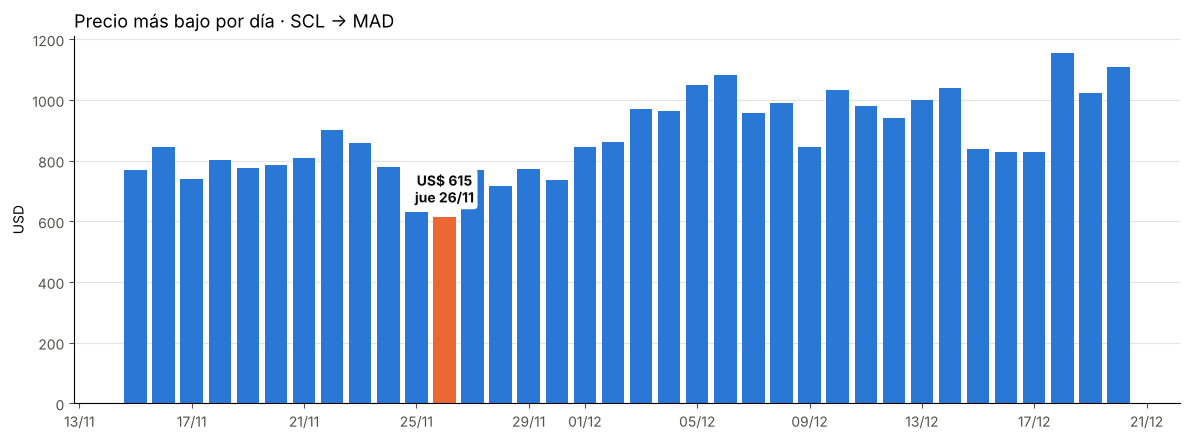

Mejor día: jue 2026-11-26 con LATAM (LIM) por US$ 615


In [4]:
por_dia = bv.mas_barato_por_dia(vuelos)
mejor = por_dia.loc[por_dia["precio_usd"].idxmin()]

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"
colores = [NARANJA if f == mejor["fecha"] else AZUL for f in por_dia["fecha"]]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(pd.to_datetime(por_dia["fecha"]), por_dia["precio_usd"], color=colores, width=0.8)
ax.annotate(f"US$ {mejor['precio_usd']}\n{mejor['dia']} {mejor['fecha']:%d/%m}",
            xy=(pd.to_datetime(mejor["fecha"]), mejor["precio_usd"]),
            xytext=(0, 8), textcoords="offset points", ha="center", va="bottom",
            fontsize=10, fontweight="bold", color="#0b0b0b",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none"))
ax.set_title(f"Precio más bajo por día · {ORIGEN} → {DESTINO}", loc="left", fontsize=13)
ax.set_ylabel("USD")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(colors=GRIS)
plt.tight_layout()
plt.show()

print(f"Mejor día: {mejor['dia']} {mejor['fecha']} con {mejor['aerolinea']} "
      f"({mejor['via']}) por US$ {mejor['precio_usd']}")

### ¿Qué día de la semana conviene volar?

In [5]:
(por_dia.groupby("dia", sort=False)["precio_usd"]
 .agg(["mean", "min", "count"]).round(0)
 .reindex(bv.DIAS_SEMANA).dropna()
 .rename(columns={"mean": "promedio_usd", "min": "minimo_usd", "count": "dias"})
 .sort_values("promedio_usd"))

,promedio_usd,minimo_usd,dias
dia,,,
mié,794.0,632,5
mar,839.0,740,5
jue,844.0,615,5
lun,887.0,736,5
sáb,908.0,718,5
vie,931.0,770,5
dom,939.0,768,6


### Comparación por aerolínea

In [6]:
(vuelos.groupby("aerolinea")
 .agg(precio_min=("precio_usd", "min"), precio_promedio=("precio_usd", "mean"),
      duracion_promedio_h=("duracion_h", "mean"), vuelos=("precio_usd", "size"))
 .round(1).sort_values("precio_min"))

,precio_min,precio_promedio,duracion_promedio_h,vuelos
aerolinea,,,,
LATAM,615,984.3,16.7,55
Air France,677,1030.0,19.7,72
Iberia,743,1161.0,13.9,75


## 4. Mejores combinaciones de ida y vuelta

In [7]:
ida_vuelta = bv.buscar_ida_y_vuelta(ORIGEN, DESTINO, FECHA_DESDE, FECHA_HASTA,
                                    MIN_NOCHES, MAX_NOCHES, top=10, **FILTROS)
ida_vuelta

,fecha_ida,dia_ida,aerolinea_ida,via_ida,precio_usd_ida,fecha_vuelta,dia_vuelta,aerolinea_vuelta,via_vuelta,precio_usd_vuelta,noches,precio_total_usd
0,2026-11-26,jue,LATAM,LIM,615,2026-12-09,mié,LATAM,BOG,725,13,1340
1,2026-11-25,mié,LATAM,GRU,632,2026-12-09,mié,LATAM,BOG,725,14,1357
2,2026-11-17,mar,LATAM,GRU,740,2026-11-25,mié,LATAM,LIM,652,8,1392
3,2026-11-17,mar,LATAM,GRU,740,2026-11-26,jue,Air France,CDG,667,9,1407
4,2026-11-17,mar,LATAM,GRU,740,2026-11-24,mar,Air France,CDG,674,7,1414
5,2026-11-15,dom,LATAM,BOG,768,2026-11-25,mié,LATAM,LIM,652,10,1420
6,2026-11-15,dom,LATAM,BOG,768,2026-11-26,jue,Air France,CDG,667,11,1435
7,2026-11-19,jue,LATAM,BOG,775,2026-11-26,jue,Air France,CDG,667,7,1442
8,2026-11-15,dom,LATAM,BOG,768,2026-11-24,mar,Air France,CDG,674,9,1442
9,2026-11-28,sáb,LATAM,LIM,718,2026-12-09,mié,LATAM,BOG,725,11,1443


## 5. Explorar destinos: ¿a dónde puedo ir barato?

El vuelo más económico desde el origen a cada destino en el período.
`usd_por_1000km` ayuda a encontrar *ofertas* (lejos pero barato).

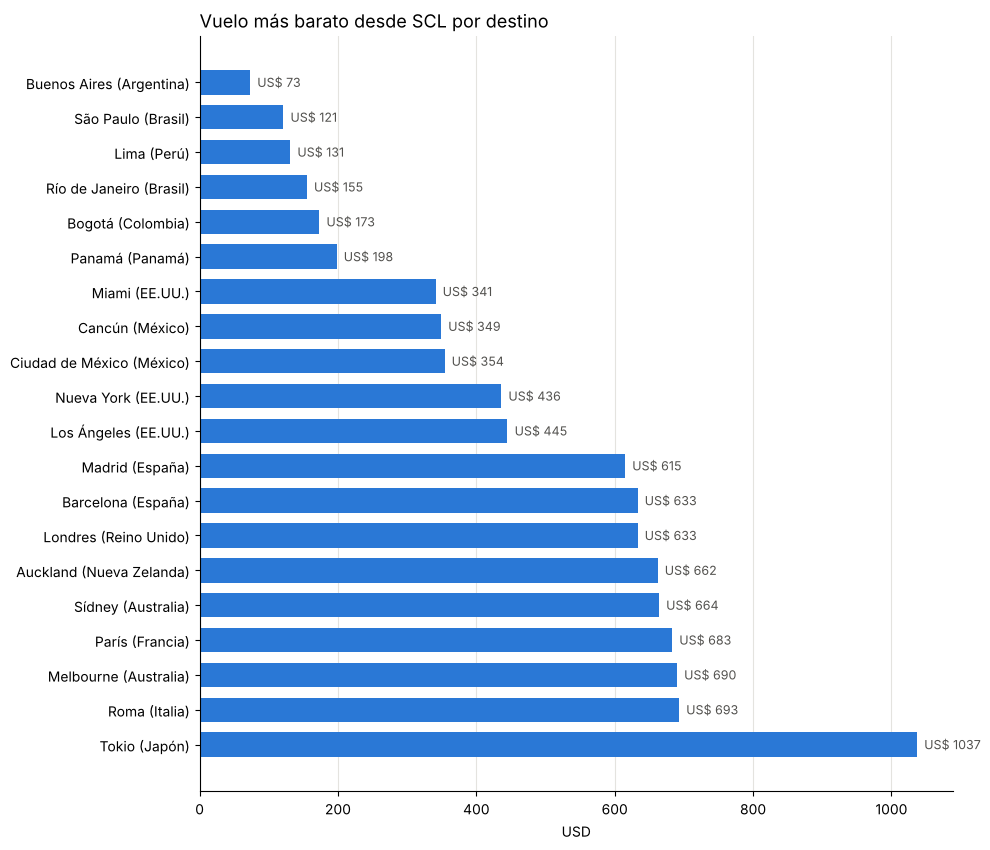

,destino,ciudad,fecha,dia,aerolinea,via,duracion_h,precio_usd,usd_por_1000km
0,EZE,Buenos Aires (Argentina),2026-11-25,mié,JetSMART,directo,1.9,73,64.1
1,GRU,São Paulo (Brasil),2026-11-25,mié,JetSMART,EZE,7.3,121,46.3
2,LIM,Lima (Perú),2026-11-26,jue,JetSMART,directo,3.6,131,53.2
3,GIG,Río de Janeiro (Brasil),2026-11-24,mar,JetSMART,directo,4.2,155,52.8
4,BOG,Bogotá (Colombia),2026-11-26,jue,JetSMART,LIM,8.6,173,40.7
5,PTY,Panamá (Panamá),2026-11-17,mar,JetSMART,LIM,9.6,198,41.2
6,MIA,Miami (EE.UU.),2026-11-26,jue,Aerolíneas Argentinas,EZE,14.5,341,51.2
7,CUN,Cancún (México),2026-11-17,mar,Copa Airlines,PTY,12.3,349,55.5
8,MEX,Ciudad de México (México),2026-11-26,jue,Avianca,BOG,12.8,354,53.7
9,JFK,Nueva York (EE.UU.),2026-11-24,mar,Aerolíneas Argentinas,EZE,14.3,436,52.9


In [8]:
destinos = bv.explorar_destinos(ORIGEN, FECHA_DESDE, FECHA_HASTA, **FILTROS)

fig, ax = plt.subplots(figsize=(10, 0.38 * len(destinos) + 1))
ax.barh(destinos["ciudad"], destinos["precio_usd"], color=AZUL, height=0.7)
for y, precio in enumerate(destinos["precio_usd"]):
    ax.text(precio + destinos["precio_usd"].max() * 0.01, y, f"US$ {precio}",
            va="center", fontsize=9, color=GRIS)
ax.invert_yaxis()
ax.set_title(f"Vuelo más barato desde {ORIGEN} por destino", loc="left", fontsize=13)
ax.set_xlabel("USD")
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

destinos

## 6. Guardar resultados

Exporta los vuelos encontrados a CSV para revisarlos en Excel.

In [9]:
archivo = f"vuelos_{ORIGEN}_{DESTINO}_{FECHA_DESDE}_{FECHA_HASTA}.csv"
vuelos.to_csv(archivo, index=False)
print("Guardado en", archivo)

Guardado en vuelos_SCL_MAD_2026-11-15_2026-12-20.csv
